<a href="https://colab.research.google.com/github/Gilbertq1/BelajarMachineLearning2/blob/main/iot23_randomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Gathering Data

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import plotly.express as px
import networkx as nx
import plotly.graph_objects as go

## 2. Read Dataset

In [ ]:
df = pd.read_csv('/content/iot23_combined_new.csv', low_memory=False)

# Exploratory Data Analysis

## 1. Menampilkan 5 Data Pertama dan Terakhir

In [ ]:
df.head()

,Unnamed: 0,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,...,conn_state,local_orig,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
0,0,1.536227e+09,CeqqKl3hyLQmO8LK98,192.168.100.111,17576.0,78.1.220.212,8081.0,tcp,-,3e-06,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
1,1,1.536227e+09,C2oHQWo1EFGH8D9x7,192.168.100.111,17576.0,152.84.7.111,8081.0,tcp,-,2e-06,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
2,2,1.536227e+09,CJLVjs4BByG04mczXc,192.168.100.111,17576.0,173.36.41.67,8081.0,tcp,-,2e-06,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
3,3,1.536227e+09,C0z4uS9AWHDH2s4S7,192.168.100.111,17576.0,87.13.21.104,8081.0,tcp,-,2e-06,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
4,4,1.536227e+09,CxbNVk3liFNUIlqSPi,192.168.100.111,17576.0,99.110.163.140,8081.0,tcp,-,2e-06,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan


In [ ]:
df.tail()

,Unnamed: 0,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,...,conn_state,local_orig,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
6046618,122,1.562165e+09,CbiAr234EfpzQInxbg,0.0.0.0,68.0,255.255.255.255,67.0,udp,dhcp,90.034713,...,S0,-,-,0.0,D,11.0,3608.0,0.0,0.0,Benign
6046619,123,1.562165e+09,CqEhZf1lYmVokqECn3,::,143.0,ff02::16,0.0,icmp,-,90.39997,...,OTH,-,-,0.0,-,9.0,844.0,0.0,0.0,Benign
6046620,124,1.562165e+09,Cr5vKO1CGfMQwFp22c,::,135.0,ff02::1:ffd5:cdf,136.0,icmp,-,89.82403000000001,...,OTH,-,-,0.0,-,3.0,216.0,0.0,0.0,Benign
6046621,125,1.562165e+09,CQ5cJ21U9NUbUWIznd,fe80::5bcc:698e:39d5:cdf,143.0,ff02::16,0.0,icmp,-,45.215915,...,OTH,-,-,0.0,-,8.0,648.0,0.0,0.0,Benign
6046622,126,1.562165e+09,CjD5ve2qwxfFtvd4zl,fe80::5bcc:698e:39d5:cdf,133.0,ff02::2,134.0,icmp,-,44.242222999999996,...,OTH,-,-,0.0,-,2.0,96.0,0.0,0.0,Benign


## 2. Melihat Informasi Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6046623 entries, 0 to 6046622
Data columns (total 22 columns):
 #   Column         Dtype  
---  ------         -----  
 0   Unnamed: 0     int64  
 1   ts             float64
 2   uid            object 
 3   id.orig_h      object 
 4   id.orig_p      float64
 5   id.resp_h      object 
 6   id.resp_p      float64
 7   proto          object 
 8   service        object 
 9   duration       object 
 10  orig_bytes     object 
 11  resp_bytes     object 
 12  conn_state     object 
 13  local_orig     object 
 14  local_resp     object 
 15  missed_bytes   float64
 16  history        object 
 17  orig_pkts      float64
 18  orig_ip_bytes  float64
 19  resp_pkts      float64
 20  resp_ip_bytes  float64
 21  label          object 
dtypes: float64(8), int64(1), object(13)
memory usage: 1014.9+ MB


Terdapat total 22 columns pada dataframe yang mana masing-masing ada yang ber-type data float, int, dan object

## 3. Melihat Dimensi Dataset

In [ ]:
df.shape

(6046623, 22)

Dataframe yang digunakan berbentuk matriks 6046623x22

## 4. Melihat Tipe Data Tiap Kolom

In [ ]:
df.dtypes

Unnamed: 0         int64
ts               float64
uid               object
id.orig_h         object
id.orig_p        float64
id.resp_h         object
id.resp_p        float64
proto             object
service           object
duration          object
orig_bytes        object
resp_bytes        object
conn_state        object
local_orig        object
local_resp        object
missed_bytes     float64
history           object
orig_pkts        float64
orig_ip_bytes    float64
resp_pkts        float64
resp_ip_bytes    float64
label             object
dtype: object

## 5. Melihat Jumlah Data Unik

In [ ]:
df.nunique()

Unnamed: 0        499999
ts               6046623
uid              6046623
id.orig_h           1494
id.orig_p          65536
id.resp_h        4979000
id.resp_p            697
proto                  3
service                7
duration           48920
orig_bytes           439
resp_bytes           377
conn_state            13
local_orig             1
local_resp             1
missed_bytes          23
history              140
orig_pkts            181
orig_ip_bytes        712
resp_pkts            128
resp_ip_bytes        472
label                 13
dtype: int64

## 6. Melihat Statistik Deskriptif

In [ ]:
df.describe()

,Unnamed: 0,ts,id.orig_p,id.resp_p,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes
count,6.046623e+06,6.046623e+06,6.046623e+06,6.046623e+06,6.046623e+06,6.046623e+06,6.046623e+06,6.046623e+06,6.046623e+06
mean,2.481276e+05,1.546218e+09,3.603571e+04,1.897556e+04,5.090908e-02,4.375558e+01,1.907296e+03,5.875329e-02,6.426806e+01
std,1.453392e+05,9.546116e+06,1.776917e+04,2.273121e+04,2.108386e+01,3.534218e+04,1.392789e+06,9.774769e+01,1.422790e+05
min,0.000000e+00,1.532101e+09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.220850e+05,1.537541e+09,2.256800e+04,2.300000e+01,0.000000e+00,1.000000e+00,4.000000e+01,0.000000e+00,0.000000e+00
50%,2.480560e+05,1.545433e+09,3.618500e+04,8.081000e+03,0.000000e+00,1.000000e+00,4.000000e+01,0.000000e+00,0.000000e+00
75%,3.740270e+05,1.551383e+09,5.084000e+04,3.721500e+04,0.000000e+00,2.000000e+00,8.000000e+01,0.000000e+00,0.000000e+00
max,4.999980e+05,1.569018e+09,6.553500e+04,6.549000e+04,2.027200e+04,6.602735e+07,1.914793e+09,2.394840e+05,3.496187e+08


## 7. Cek Missing Values

In [ ]:
df.isna().sum()

Unnamed: 0       0
ts               0
uid              0
id.orig_h        0
id.orig_p        0
id.resp_h        0
id.resp_p        0
proto            0
service          0
duration         0
orig_bytes       0
resp_bytes       0
conn_state       0
local_orig       0
local_resp       0
missed_bytes     0
history          0
orig_pkts        0
orig_ip_bytes    0
resp_pkts        0
resp_ip_bytes    0
label            0
dtype: int64

Saat cek menggunakan isna memang tidak terlihat adanya missing values, namun saat dilihat secara langsung pada dataset nya maka akan ditemukan beberapa kolom yang tidak terisi. Walaupun terisi pun kadang hanya berisi value "-", "0.0", ataupun "::"

## 8. Check Unique per Column

tidak ada missing value, namun terdapat kolom yang hanya berisikan "-" pada keseluruhan baris nya.

In [ ]:
df.apply(lambda col: col.unique())

Unnamed: 0       [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...
ts               [1536227023.384673, 1536227023.384678, 1536227...
uid              [CeqqKl3hyLQmO8LK98, C2oHQWo1EFGH8D9x7, CJLVjs...
id.orig_h        [192.168.100.111, 197.13.3.22, 212.234.209.150...
id.orig_p        [17576.0, 17832.0, 18344.0, 18088.0, 41722.0, ...
id.resp_h        [78.1.220.212, 152.84.7.111, 173.36.41.67, 87....
id.resp_p        [8081.0, 37215.0, 52869.0, 8080.0, 80.0, 666.0...
proto                                             [tcp, udp, icmp]
service                        [-, dns, http, irc, dhcp, ssl, ssh]
duration         [3e-06, 2e-06, 6e-06, 0.00022200000000000003, ...
orig_bytes       [0, 96, 80, 56, 88, 136, 1008, 168, 84, 78, 90...
resp_bytes       [0, 96, 2496, 444, 90, 103, -, 45, 39, 55, 48,...
conn_state       [S0, REJ, RSTO, SF, OTH, RSTOS0, RSTR, S1, S2,...
local_orig                                                     [-]
local_resp                                                    

# Cek Semua Kolom untuk Memastikan Missing Values

## 1. Menampilkan Keseluruhan Kolom

In [ ]:
df.columns

Index(['Unnamed: 0', 'ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h',
       'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes',
       'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history',
       'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'label'],
      dtype='object')

## 2. Cek Kolom Label

In [ ]:
df['label'].unique()

array(['PartOfAHorizontalPortScan', 'Okiru', 'DDoS', 'C&C-HeartBeat',
       'Benign', 'C&C-Torii', 'C&C', 'C&C-FileDownload', 'Okiru-Attack',
       'Attack', 'FileDownload', 'C&C-HeartBeat-FileDownload',
       'C&C-Mirai'], dtype=object)

In [ ]:
df['label'].value_counts()

label
PartOfAHorizontalPortScan     3389036
Okiru                         1313012
Benign                         688812
DDoS                           638506
C&C                             15286
C&C-HeartBeat                    1332
Attack                            538
C&C-FileDownload                   46
C&C-Torii                          30
FileDownload                       13
C&C-HeartBeat-FileDownload          8
Okiru-Attack                        3
C&C-Mirai                           1
Name: count, dtype: int64

## 3. Cek Kolom local_orig

In [ ]:
df['local_orig'].unique()

array(['-'], dtype=object)

In [ ]:
df['local_orig'].value_counts()

local_orig
-    6046623
Name: count, dtype: int64

## 4. Cek Kolom local_resp

In [ ]:
df['local_resp'].unique()

array(['-'], dtype=object)

In [ ]:
df['local_resp'].value_counts()

local_resp
-    6046623
Name: count, dtype: int64

## 5. Cek Kolom id.orig_h

In [ ]:
df['id.orig_h'].unique()

array(['192.168.100.111', '197.13.3.22', '212.234.209.150', ...,
       'fe80::6a05:71ff:fe67:dff2', 'fe80::18:e207:b314:641b',
       'fe80::211:32ff:fe8d:ffe2'], dtype=object)

In [ ]:
df['id.orig_h'].value_counts()

id.orig_h
192.168.1.197      1004274
192.168.1.198       999940
192.168.100.111     999711
192.168.1.195       522846
192.168.1.194       499990
                    ...   
120.80.201.14            1
84.63.59.168             1
179.86.71.177            1
123.60.157.103           1
62.55.151.88             1
Name: count, Length: 1494, dtype: int64

## 6. Cek Kolom conn_state

In [ ]:
df['conn_state'].unique()

array(['S0', 'REJ', 'RSTO', 'SF', 'OTH', 'RSTOS0', 'RSTR', 'S1', 'S2',
       'S3', 'SH', 'SHR', 'RSTRH'], dtype=object)

In [ ]:
df['conn_state'].value_counts()

conn_state
S0        5514038
OTH        515339
SF          11653
REJ          2488
S3           2484
RSTR          334
SH            105
RSTO          100
RSTOS0         44
S1             16
SHR            14
S2              6
RSTRH           2
Name: count, dtype: int64

## 7. Heatmap

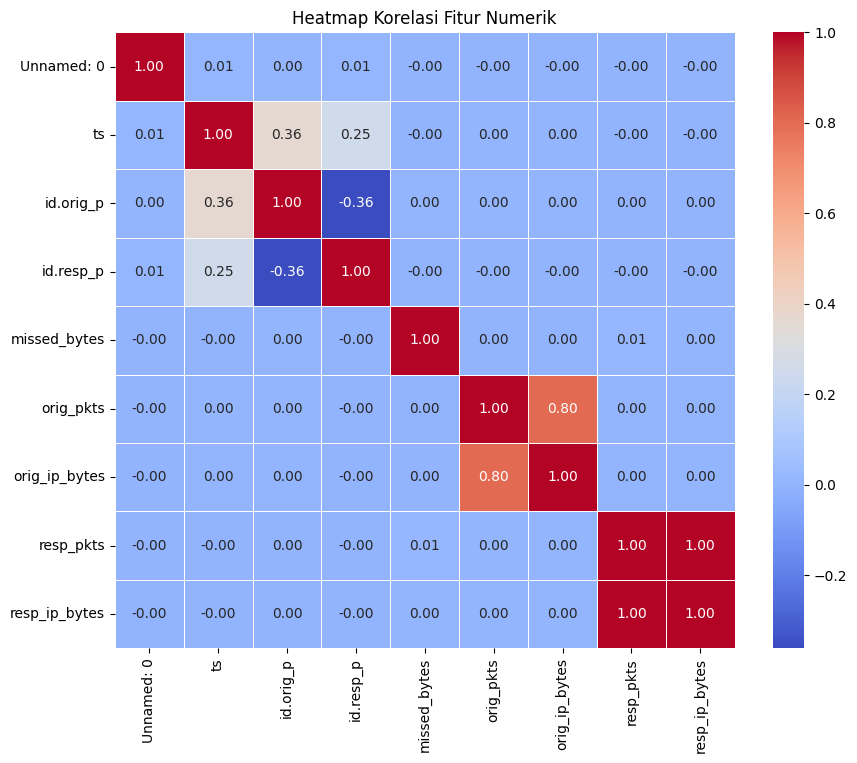

In [ ]:
# Hitung korelasi antar fitur numerik
correlation_matrix = df.corr(numeric_only=True)

# Buat heatmap
plt.figure(figsize=(10, 8))  # ukuran gambar heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

# Data Distribution

## a. Distribution of Network Events by Label

In [ ]:
event_label_counts = df['label'].value_counts()
event_df = event_label_counts.reset_index()
event_df.columns = ['label', 'frequency']

fig = px.bar(
    event_df.sort_values(by='frequency', ascending=False),
    x='label',
    y='frequency',
    title='Distribution of Network Events by Label',
    labels={'frequency': 'Frequency', 'label': 'Event Label'},
    log_y=True,  # aktifkan skala logaritmik
    color='label'
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

Penjelasan dari masing-masing label:
* PartOfAHorizontalPortScan: A large number of connection attempts to various ports across multiple hosts, typically to discover open ports and vulnerable services. This activity is a common precursor to more targeted attacks.
* Okiru: Associated with the Okiru malware, which targets IoT devices. Okiru is known for its capability to infect routers and other connected devices.
* Benign: Normal, non-malicious network traffic that does not pose a security threat. This label is crucial for training models to distinguish between harmful and harmless activities.
* DDoS (Distributed Denial of Service): Traffic patterns indicative of a DDoS attack, where multiple systems flood the bandwidth or resources of a targeted system, usually one or more web servers.
* C&C (Command and Control): Traffic associated with command and control servers, which attackers use to communicate with and control compromised systems within a botnet or malware-infected network.
* C&C-HeartBeat: A specific type of C&C traffic that involves periodic signals (heartbeats) sent from compromised devices to a C&C server to indicate the device is still active and connected.
* Attack: A general label for traffic that is part of a network attack, which could involve unauthorized access, data exfiltration, or other malicious activities.
* C&C-FileDownload: Traffic indicating that a compromised device is downloading files from a C&C server, potentially indicating the download of malware, updates to existing malware, or malicious configurations.
* C&C-Torii: Activity related to the Torii botnet, which is known for its sophisticated design and versatility in targeting various platforms and devices.
* FileDownload: Indicates the download of files, which in this context may be considered suspicious or part of malicious activities, especially if associated with known malware distribution patterns.
* C&C-HeartBeat-FileDownload: A combination of heartbeats to a C&C server and file downloads from the same, indicating ongoing control and updating of malware or malicious tools on compromised devices.
* Okiru-Attack: Specific attack patterns associated with the Okiru malware, likely indicating active exploitation attempts or malicious activities carried out by infected devices.
* C&C-Mirai: Traffic related to the Mirai botnet, which infects IoT devices to perform large-scale DDoS attacks. Mirai is notorious for exploiting default username and password combinations on IoT devices.

## b. Protocol Usage Frequency

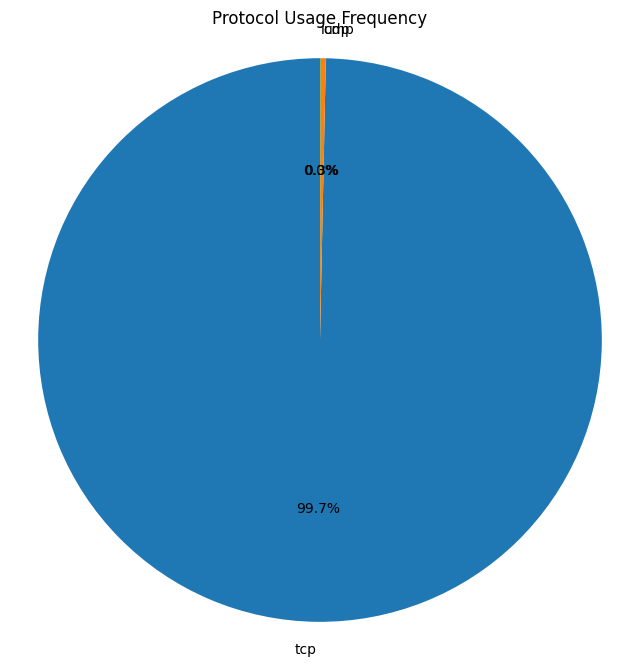

In [ ]:
protocol_usage_counts = df['proto'].value_counts()

# Visualization: Pie chart showing the proportion of each protocol used
plt.figure(figsize=(8, 8))  # Adjust figure size as needed
plt.pie(protocol_usage_counts, labels=protocol_usage_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Protocol Usage Frequency')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.show()

Dari analisis di atas, ternyata jelas bahwa tcp sering digunakan untuk koneksi sebanyak lebih dari 99% connection attempts.

## c. Connection Duration by Label

In [ ]:
import warnings

# Menonaktifkan RuntimeWarning
warnings.filterwarnings('ignore', category=RuntimeWarning)

In [ ]:
df['duration'] = pd.to_numeric(df['duration'], errors='coerce')
# Group by 'event_label' and calculate summary statistics for 'connection_duration'
connection_duration_by_label = df.groupby('label')['duration'].describe()

# You might be specifically interested in certain statistics, like mean and median:
mean_connection_duration_by_label = df.groupby('label')['duration'].mean()
median_connection_duration_by_label = df.groupby('label')['duration'].median()

# Print the summary statistics
print("Summary Statistics of Connection Duration by Label:")
print(connection_duration_by_label)

Summary Statistics of Connection Duration by Label:
                                count          mean           std       min  \
label                                                                         
Attack                          538.0      5.245452     27.767583  0.013494   
Benign                       265895.0      4.233314    218.334890  0.000001   
C&C                            6604.0     20.160268    653.901673  0.000002   
C&C-FileDownload                 46.0      1.769612      1.076810  0.600404   
C&C-HeartBeat                   910.0      1.793607      1.459489  0.000005   
C&C-HeartBeat-FileDownload        8.0      1.235697      0.402674  0.856751   
C&C-Mirai                         1.0      0.329079           NaN  0.329079   
C&C-Torii                        16.0  10724.311400  17053.609237  1.191069   
DDoS                         124977.0      0.284862     30.298576  0.000001   
FileDownload                     13.0      6.692524     15.640581  0.569426   


In [ ]:


# Asumsikan kamu sudah punya Series mean_connection_duration_by_label
# Ubah ke DataFrame agar bisa dipakai plotly
mean_duration_df = mean_connection_duration_by_label.reset_index()
mean_duration_df.columns = ['label', 'mean_connection_duration']

# (Opsional) Drop outlier kalau mau
# mean_duration_df = mean_duration_df[mean_duration_df['label'] != 'C&C-Torii']

# Plot interaktif
fig = px.bar(
    mean_duration_df.sort_values(by='mean_connection_duration', ascending=True),
    x='mean_connection_duration',
    y='label',
    orientation='h',
    title='Mean Connection Duration by Label (Interaktif)',
    labels={'mean_connection_duration': 'Durasi Rata-rata (detik)', 'label': 'Event Label'},
    hover_data=['mean_connection_duration']
)

fig.update_layout(
    height=600,
    xaxis_type='log',  # ganti ke 'linear' kalau tidak pakai skala log
    bargap=0.2
)

fig.show()


The summary statistics provide insight into the distribution of connection durations within each label category, measured in seconds. Key metrics include the count (number of events), mean (average duration), standard deviation (variability), minimum, and maximum durations, along with the first (25%), second (50%, median), and third (75%) quartiles.

Benign Traffic: Exhibits a wide range of durations with a significant standard deviation, indicating varied lengths of benign connections. The presence of extremely long durations (max of 78840.33 seconds) suggests some benign activities involve prolonged connections.

Malicious Activities ('Attack', 'DDoS', 'C&C', etc.): These labels show a diverse range of mean durations. 'C&C-Torii' stands out with an exceptionally high mean duration (10724.31 seconds), significantly influenced by outliers, as reflected by its large standard deviation. This suggests some C&C activities maintain long-lasting connections, possibly to ensure sustained control over compromised devices.

'PartOfAHorizontalPortScan': Characterized by short durations (mean of 0.444 seconds), consistent with the nature of port scanning activities, which typically involve brief connection attempts to multiple ports.

'Okiru' and 'Okiru-Attack': These labels are associated with very short mean durations for 'Okiru' and significantly longer durations for 'Okiru-Attack', highlighting the difference in behavior between regular malware activity and active attack phases.

## d. Identifying Top Communicating Pair

identifikasi pasangan dari source_ip_address dan destination_ip_address dengan koneksi terbanyak

In [ ]:
pair_counts = df.groupby(['id.orig_h', 'id.resp_h']).size().reset_index(name='connections')

# Sort pairs by the number of connections, descending
top_pairs = pair_counts.sort_values(by='connections', ascending=False).head(10)

print(top_pairs)

               id.orig_h        id.resp_h  connections
996489     192.168.1.195   162.248.88.215       499142
996484     192.168.1.195   123.59.209.185        14260
996495     192.168.1.195   185.244.25.235         6768
4987352  192.168.100.113  178.128.185.250         4112
4987347  192.168.100.113   128.185.250.50         4110
1632943    192.168.1.197   185.244.25.183         1947
4987355  192.168.100.113    192.168.100.1         1872
1658612    192.168.1.197      192.168.1.1         1681
4987350  192.168.100.113    147.231.100.5         1334
3491124  192.168.100.103    217.30.75.147         1301


In [ ]:
G = nx.Graph()

# Buat graph dari data komunikasi IP
top_communications = df[['id.orig_h', 'id.resp_h']].value_counts().reset_index()
top_communications.columns = ['source', 'target', 'count']
top_communications = top_communications.head(50)

# Buat graph
G = nx.from_pandas_edgelist(top_communications, 'source', 'target', edge_attr='count')

# Ambil posisi node untuk layout
pos = nx.spring_layout(G, k=0.5)

# Buat edge trace
edge_x, edge_y = [], []
for edge in G.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x, y=edge_y,
    line=dict(width=0.5, color='#888'),
    hoverinfo='none',
    mode='lines'
)

# Buat node trace
node_x, node_y, node_text = [], [], []
for node in G.nodes():
    x, y = pos[node]
    node_x.append(x)
    node_y.append(y)
    node_text.append(f"IP: {node} | Degree: {G.degree[node]}")

node_trace = go.Scatter(
    x=node_x, y=node_y,
    mode='markers+text',
    hoverinfo='text',
    text=node_text,
    textposition='top center',
    marker=dict(
        showscale=True,
        colorscale='YlGnBu',
        color=[G.degree[n] for n in G.nodes()],
        size=15,
        colorbar=dict(thickness=15, title='Node Degree', xanchor='left', titleside='right')
    )
)

# Gabung semua ke plot
fig = go.Figure(data=[edge_trace, node_trace],
             layout=go.Layout(
                title='Top Communicating IP Pairs ',
                titlefont_size=16,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20,l=5,r=5,t=40),
                annotations=[ dict(text="Network graph", showarrow=False, xref="paper", yref="paper") ],
                xaxis=dict(showgrid=False, zeroline=False),
                yaxis=dict(showgrid=False, zeroline=False)
))

fig.show()

In [ ]:
# 1. Ambil kolom yang dibutuhkan
df_subset = df[['id.orig_h', 'id.resp_h', 'label', 'conn_state']]
df_subset = df_subset.dropna()

# 2. Kelompokkan dan hitung frekuensi komunikasi
edge_counts = df_subset.groupby(['id.orig_h', 'id.resp_h', 'label', 'conn_state']).size().reset_index(name='count')
top_edges = edge_counts.sort_values(by='count', ascending=False).head(50)

# 3. Buat Graph
G = nx.from_pandas_edgelist(top_edges, 'id.orig_h', 'id.resp_h', edge_attr=True, create_using=nx.Graph())

# 4. Posisi node
pos = nx.spring_layout(G, k=0.7)

# 5. Buat edge trace (dengan warna berdasar conn_state)
edge_x, edge_y, edge_text, edge_color = [], [], [], []

state_colors = {
    'S0': 'gray', 'SF': 'blue', 'REJ': 'red',
    'RSTO': 'orange', 'RSTOS0': 'purple'
}

for u, v, data in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    edge_x += [x0, x1, None]
    edge_y += [y0, y1, None]
    conn_state = data.get('conn_state', 'Unknown')
    label = data.get('label', 'Unknown')
    edge_text.append(f"{u} → {v}<br>Label: {label}<br>State: {conn_state}<br>Count: {data.get('count')}")
    edge_color.append(state_colors.get(conn_state, 'black'))

edge_trace = go.Scatter(
    x=edge_x, y=edge_y,
    line=dict(width=1, color='gray'),
    hoverinfo='text',
    text=edge_text,
    mode='lines'
)

# 6. Buat node trace
node_x, node_y, node_text, node_color = [], [], [], []

attack_labels = [
    'PartOfAHorizontalPortScan', 'Okiru', 'DDoS', 'C&C-HeartBeat',
    'C&C-Torii', 'C&C', 'C&C-FileDownload', 'Okiru-Attack', 'Attack',
    'FileDownload', 'C&C-HeartBeat-FileDownload', 'C&C-Mirai'
]

# Pewarnaan node
for node in G.nodes():
    x, y = pos[node]
    node_x.append(x)
    node_y.append(y)

    # Ambil semua label dari edge yang terhubung
    connected_labels = set()
    for neighbor in G[node]:
        edge_data = G[node][neighbor]
        if isinstance(edge_data, dict):
            connected_labels.add(edge_data.get('label', 'Unknown'))

    # Jika ada satu pun label attack, warnai merah
    is_attack = any(lbl in attack_labels for lbl in connected_labels)
    node_color.append('red' if is_attack else 'green')

    node_text.append(f"{node}<br>Labels: {', '.join(connected_labels)}")

node_trace = go.Scatter(
    x=node_x, y=node_y,
    mode='markers+text',
    text=node_text,
    hoverinfo='text',
    marker=dict(
        size=15,
        color=node_color,
        line=dict(width=2)
    )
)

# 7. Plot final
fig = go.Figure(data=[edge_trace, node_trace],
                layout=go.Layout(
                    title='Top IP Communication Graph with Label & Connection State',
                    titlefont_size=16,
                    showlegend=False,
                    hovermode='closest',
                    margin=dict(b=20,l=5,r=5,t=40),
                    xaxis=dict(showgrid=False, zeroline=False),
                    yaxis=dict(showgrid=False, zeroline=False))
)

fig.show()

In [ ]:
for i, (source, destination, data) in enumerate(G.edges(data=True)):
    label = data.get('label', 'Unknown')
    conn_state = data.get('conn_state', 'Unknown')
    count = data.get('count', 'N/A')

    print(f"Source: {source}, Destination: {destination}")
    print(f"  Connections: {count}")
    print(f"  Label: {label}")
    print(f"  Conn State: {conn_state}")
    print('-' * 50)

    if i == 4:  # Stop
        break

Source: 192.168.1.195, Destination: 162.248.88.215
  Connections: 286
  Label: Benign
  Conn State: OTH
--------------------------------------------------
Source: 192.168.1.195, Destination: 123.59.209.185
  Connections: 14260
  Label: DDoS
  Conn State: OTH
--------------------------------------------------
Source: 192.168.1.195, Destination: 185.244.25.235
  Connections: 1584
  Label: C&C
  Conn State: S3
--------------------------------------------------
Source: 192.168.1.195, Destination: 147.231.100.5
  Connections: 702
  Label: Benign
  Conn State: SF
--------------------------------------------------
Source: 192.168.1.195, Destination: 192.168.1.1
  Connections: 150
  Label: Benign
  Conn State: S0
--------------------------------------------------


## e. Distribution of Packet Sent by Source and Destination

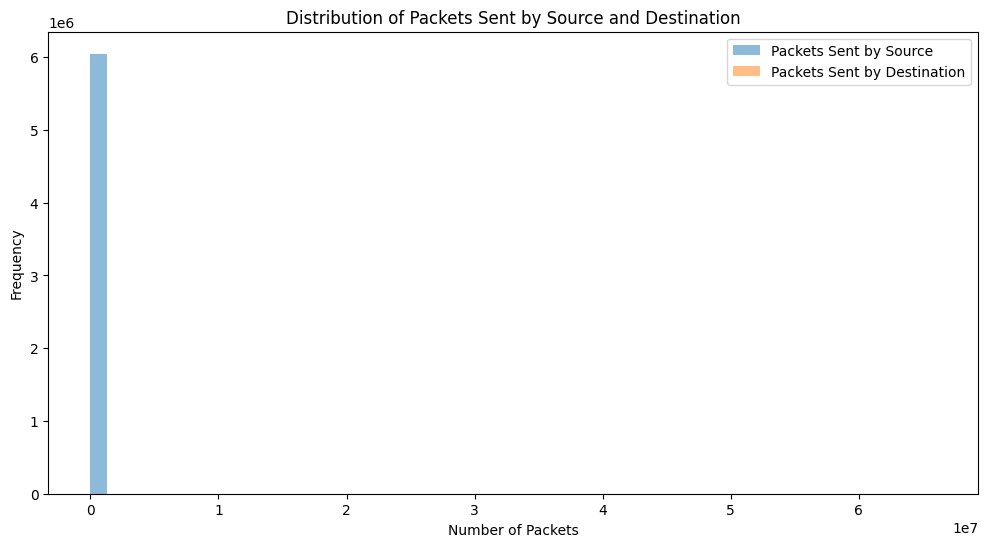

In [ ]:
df['orig_pkts'] = pd.to_numeric(df['orig_pkts'], errors='coerce')
df['resp_pkts'] = pd.to_numeric(df['resp_pkts'], errors='coerce')

plt.figure(figsize=(12, 6))

# Plot histograms for packets sent by source and destination
plt.hist(df['orig_pkts'], bins=50, alpha=0.5, label='Packets Sent by Source')
plt.hist(df['resp_pkts'], bins=500, alpha=0.5, label='Packets Sent by Destination')

plt.xlabel('Number of Packets')
plt.ylabel('Frequency')
plt.title('Distribution of Packets Sent by Source and Destination')
plt.legend()

plt.show()

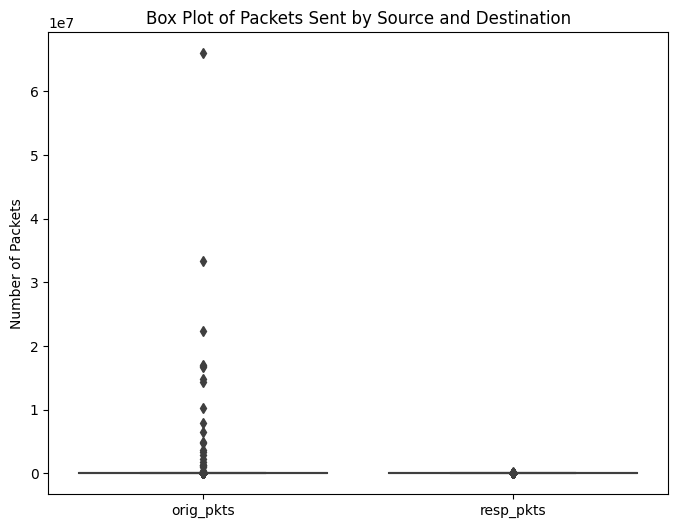

In [ ]:
plt.figure(figsize=(8, 6))

# Melting the DataFrame for easier plotting with seaborn
packets_melted = df.melt(value_vars=['orig_pkts', 'resp_pkts'], var_name='Type', value_name='Packets')

# Plotting with seaborn
sns.boxplot(x='Type', y='Packets', data=packets_melted)
plt.title('Box Plot of Packets Sent by Source and Destination')
plt.xlabel('')
plt.ylabel('Number of Packets')

plt.show()

## f. Connection States Frequency

In [ ]:
connection_states_freq = df['conn_state'].value_counts()

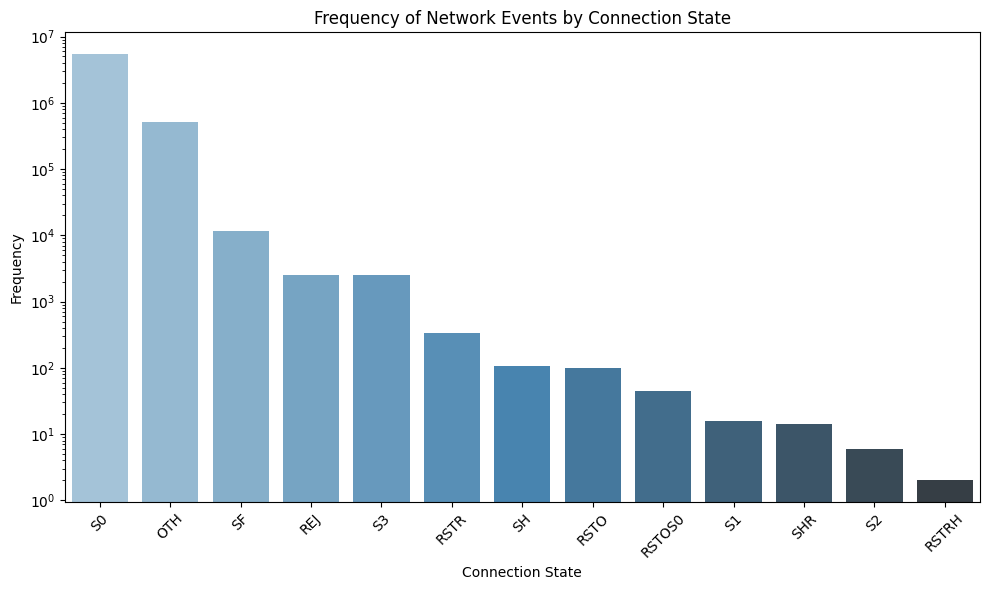

In [ ]:
# Plot histogram with log scale for better visualization of smaller frequencies
plt.figure(figsize=(10, 6))
sns.barplot(x=connection_states_freq.index, y=connection_states_freq.values, palette='Blues_d')

plt.xlabel('Connection State')
plt.ylabel('Frequency')
plt.title('Frequency of Network Events by Connection State')

# Set the y-axis to a logarithmic scale to show the distribution more clearly
plt.yscale('log')

plt.xticks(rotation=45)  # Rotate labels for readability

plt.tight_layout()
plt.show()


In [ ]:
connection_states_freq

conn_state
S0        5514038
OTH        515339
SF          11653
REJ          2488
S3           2484
RSTR          334
SH            105
RSTO          100
RSTOS0         44
S1             16
SHR            14
S2              6
RSTRH           2
Name: count, dtype: int64

In [ ]:
# Check the total number of records (rows) in your DataFrame
total_records = len(df)
print(f"Total records in the dataset: {total_records}")

Total records in the dataset: 6046623


In [ ]:
# Check the minimum and maximum frequency of connection states
print(f"Min frequency: {connection_states_freq.min()}")
print(f"Max frequency: {connection_states_freq.max()}")


Min frequency: 2
Max frequency: 5514038


# Data Preprocessing

In [ ]:
df.head()

,Unnamed: 0,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,...,conn_state,local_orig,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
0,0,1.536227e+09,CeqqKl3hyLQmO8LK98,192.168.100.111,17576.0,78.1.220.212,8081.0,tcp,-,0.000003,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
1,1,1.536227e+09,C2oHQWo1EFGH8D9x7,192.168.100.111,17576.0,152.84.7.111,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
2,2,1.536227e+09,CJLVjs4BByG04mczXc,192.168.100.111,17576.0,173.36.41.67,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
3,3,1.536227e+09,C0z4uS9AWHDH2s4S7,192.168.100.111,17576.0,87.13.21.104,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
4,4,1.536227e+09,CxbNVk3liFNUIlqSPi,192.168.100.111,17576.0,99.110.163.140,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan


## 1. Drop Unnecessarry Columns

In [ ]:
non_useful_columns = ['Unnamed: 0', 'ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'service', 'local_orig', 'local_resp', 'history']

df.drop(non_useful_columns, axis=1, inplace=True)
df.head()

,proto,duration,orig_bytes,resp_bytes,conn_state,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
0,tcp,0.000003,0,0,S0,0.0,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
1,tcp,0.000002,0,0,S0,0.0,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
2,tcp,0.000002,0,0,S0,0.0,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
3,tcp,0.000002,0,0,S0,0.0,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
4,tcp,0.000002,0,0,S0,0.0,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan


## 2. Data Balancing

In [ ]:
def subsample(df):
    df_benign = df[df['label'] == 'Benign']
    df_malicious = df[df['label'] != 'Benign']

    print('Before subsampling: ', df_benign.shape, df_malicious.shape)

    df_malicious = df_malicious.sample(len(df_benign), random_state = 0)
    df = pd.concat([df_malicious, df_benign])
    df = df.sample(frac=1, random_state=0)

    print('After subsampling: ', df_benign.shape, df_malicious.shape)

    return df

## a. Menampilkan dimensi dari dataframe setelah dilakukan subsample

In [ ]:
df = subsample(df)
print(df.shape)

Before subsampling:  (688812, 11) (5357811, 11)
After subsampling:  (688812, 11) (688812, 11)
(1377624, 11)


## b. Visualisasi kolom "label" setelah dilakukan subsample

label
Benign                       688812
PartOfAHorizontalPortScan    435540
Okiru                        168687
DDoS                          82422
C&C                            1917
C&C-HeartBeat                   160
Attack                           76
C&C-FileDownload                  5
C&C-Torii                         4
FileDownload                      1
Name: count, dtype: int64


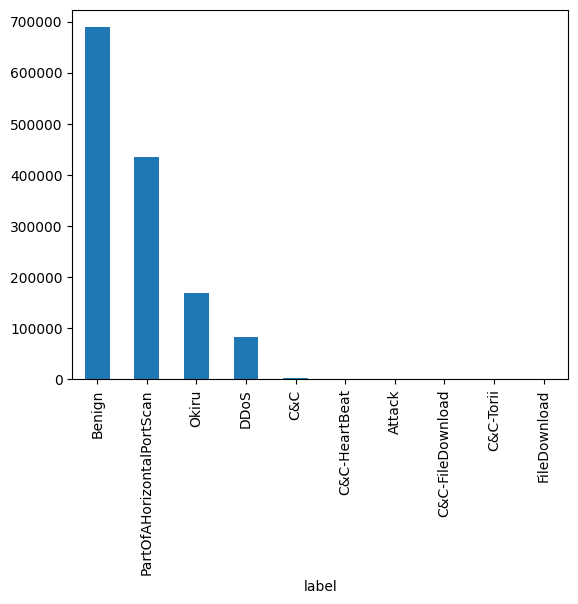

In [ ]:
print(df['label'].value_counts())
df['label'].value_counts().plot(kind='bar')
plt.show()

## c. Filter dataframe

In [ ]:
# Hitung jumlah kemunculan masing-masing label
label_counts = df['label'].value_counts()

# Ambil label yang muncul lebih dari 10 kali
valid_labels = label_counts[label_counts > 2].index

# Filter DataFrame hanya dengan label yang valid
df = df[df['label'].isin(valid_labels)]

print(label_counts)

label
Benign                       688812
PartOfAHorizontalPortScan    435540
Okiru                        168687
DDoS                          82422
C&C                            1917
C&C-HeartBeat                   160
Attack                           76
C&C-FileDownload                  5
C&C-Torii                         4
FileDownload                      1
Name: count, dtype: int64


## 3. Handle Empty Values dan One-hot Encoding

## a. Replace kolom dengan value "-" menjadi NaN

In [ ]:
import numpy as np

# Jumlah NaN sebelum replacing
print("Jumlah NaN sebelum replacing:")
print(df.isna().sum())
print()

# Mengganti nilai '-' dengan NaN
df.replace(['-'], np.nan, inplace=True)

# Jumlah NaN setelah replacing
print("Jumlah NaN setelah replacing '-':")
print(df.isna().sum())


Jumlah NaN sebelum replacing:
proto                 0
duration         853626
orig_bytes            0
resp_bytes            0
conn_state            0
missed_bytes          0
orig_pkts             0
orig_ip_bytes         0
resp_pkts             0
resp_ip_bytes         0
label                 0
dtype: int64

Jumlah NaN setelah replacing '-':
proto                 0
duration         853626
orig_bytes       853626
resp_bytes       853626
conn_state            0
missed_bytes          0
orig_pkts             0
orig_ip_bytes         0
resp_pkts             0
resp_ip_bytes         0
label                 0
dtype: int64


## b. Pilih kolom yang akan di-encode

In [ ]:
# Make 'proto', 'service', 'conn_state', 'history' as One-Hot Encoded
print(df.columns)

def encode(df, column_name):
    df[column_name] = df[column_name].astype(str)
    dummies = pd.get_dummies(df[[column_name]], dummy_na=True).astype(int)
    res = pd.concat([df, dummies], axis=1)
    res = res.drop([column_name], axis=1)
    return res

# columns_to_encode = ['proto', 'conn_state']
columns_to_encode = ['proto', 'conn_state']

for column in columns_to_encode:
    df = encode(df, column)

print(df.columns)

Index(['proto', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state',
       'missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts',
       'resp_ip_bytes', 'label'],
      dtype='object')
Index(['duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 'orig_pkts',
       'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'label', 'proto_icmp',
       'proto_tcp', 'proto_udp', 'proto_nan', 'conn_state_OTH',
       'conn_state_REJ', 'conn_state_RSTO', 'conn_state_RSTOS0',
       'conn_state_RSTR', 'conn_state_RSTRH', 'conn_state_S0', 'conn_state_S1',
       'conn_state_S2', 'conn_state_S3', 'conn_state_SF', 'conn_state_SH',
       'conn_state_SHR', 'conn_state_nan'],
      dtype='object')


In [ ]:
print(df.shape)
df.tail()

(1377623, 27)


,duration,orig_bytes,resp_bytes,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,proto_icmp,...,conn_state_RSTR,conn_state_RSTRH,conn_state_S0,conn_state_S1,conn_state_S2,conn_state_S3,conn_state_SF,conn_state_SH,conn_state_SHR,conn_state_nan
4466639,0.000001,0,0,0.0,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan,0,...,0,0,1,0,0,0,0,0,0,0
2916449,NaN,NaN,NaN,0.0,1.0,40.0,0.0,0.0,PartOfAHorizontalPortScan,0,...,0,0,1,0,0,0,0,0,0,0
1282959,NaN,NaN,NaN,0.0,1.0,60.0,0.0,0.0,Benign,0,...,0,0,1,0,0,0,0,0,0,0
52905,0.000002,0,0,0.0,2.0,80.0,0.0,0.0,Okiru,0,...,0,0,1,0,0,0,0,0,0,0
621776,NaN,NaN,NaN,0.0,1.0,40.0,0.0,0.0,Okiru,0,...,0,0,1,0,0,0,0,0,0,0


## c. Replace nilai NaN

In [ ]:
# Pisahkan kolom numerik dan kategorikal
numeric_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Tampilkan jumlah NaN sebelum replace
print("=== JUMLAH NaN SEBELUM REPLACING ===")
print(df.isna().sum()[df.isna().sum() > 0])

# Isi NaN kolom numerik dengan median
for column in numeric_cols:
    median_val = df[column].median()
    df[column] = df[column].fillna(median_val)

# Isi NaN kolom kategorikal dengan modus
for column in categorical_cols:
    mode_val = df[column].mode()[0]
    df[column] = df[column].fillna(mode_val)

# Tampilkan jumlah NaN setelah replace
print("\n=== JUMLAH NaN SETELAH REPLACING ===")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nUkuran dataset:", df.shape)
df.head()


=== JUMLAH NaN SEBELUM REPLACING ===
duration      853626
orig_bytes    853626
resp_bytes    853626
dtype: int64

=== JUMLAH NaN SETELAH REPLACING ===
Series([], dtype: int64)

Ukuran dataset: (1377623, 27)


,duration,orig_bytes,resp_bytes,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,proto_icmp,...,conn_state_RSTR,conn_state_RSTRH,conn_state_S0,conn_state_S1,conn_state_S2,conn_state_S3,conn_state_SF,conn_state_SH,conn_state_SHR,conn_state_nan
2997194,3.088270,0,0,0.0,1.0,40.0,0.0,0.0,Benign,0,...,0,0,1,0,0,0,0,0,0,0
2539872,3.088270,0,0,0.0,1.0,40.0,0.0,0.0,PartOfAHorizontalPortScan,0,...,0,0,1,0,0,0,0,0,0,0
1322831,3.158427,0,0,0.0,3.0,180.0,0.0,0.0,Benign,0,...,0,0,1,0,0,0,0,0,0,0
701413,3.088270,0,0,0.0,1.0,40.0,0.0,0.0,PartOfAHorizontalPortScan,0,...,0,0,1,0,0,0,0,0,0,0
4995502,3.088270,0,0,0.0,0.0,0.0,0.0,0.0,DDoS,0,...,0,0,0,0,0,0,0,0,0,0


## d. Remove kolom yang berisi 0

In [ ]:
empty_columns = df.columns[(df == 0).all()]
print(empty_columns)
df.drop(empty_columns, axis=1, inplace=True)
print(df.shape)
df.head()

Index(['proto_nan', 'conn_state_nan'], dtype='object')
(1377623, 25)


,duration,orig_bytes,resp_bytes,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label,proto_icmp,...,conn_state_RSTOS0,conn_state_RSTR,conn_state_RSTRH,conn_state_S0,conn_state_S1,conn_state_S2,conn_state_S3,conn_state_SF,conn_state_SH,conn_state_SHR
2997194,3.088270,0,0,0.0,1.0,40.0,0.0,0.0,Benign,0,...,0,0,0,1,0,0,0,0,0,0
2539872,3.088270,0,0,0.0,1.0,40.0,0.0,0.0,PartOfAHorizontalPortScan,0,...,0,0,0,1,0,0,0,0,0,0
1322831,3.158427,0,0,0.0,3.0,180.0,0.0,0.0,Benign,0,...,0,0,0,1,0,0,0,0,0,0
701413,3.088270,0,0,0.0,1.0,40.0,0.0,0.0,PartOfAHorizontalPortScan,0,...,0,0,0,1,0,0,0,0,0,0
4995502,3.088270,0,0,0.0,0.0,0.0,0.0,0.0,DDoS,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.reset_index(drop=True, inplace=True)

## e. Pastikan tidak ada missing value

In [ ]:
df.apply(lambda col: col.unique())

duration             [3.08827, 3.158427, 6e-06, 3.111497, 2e-06, 3....
orig_bytes           [0, 48, 29, 45, 1272, 804, 96, 78, 39, 3000, 5...
resp_bytes           [0, 48, 45, 96, 103, 1451, 62, 233, 99303, 775...
missed_bytes         [0.0, 5792.0, 2896.0, 1539.0, 4006.0, 1448.0, ...
orig_pkts            [1.0, 3.0, 0.0, 2.0, 6.0, 4.0, 12.0, 8.0, 5.0,...
orig_ip_bytes        [40.0, 180.0, 0.0, 80.0, 360.0, 60.0, 160.0, 2...
resp_pkts            [0.0, 1.0, 2.0, 3.0, 7.0, 6.0, 69.0, 5.0, 4.0,...
resp_ip_bytes        [0.0, 40.0, 76.0, 73.0, 92.0, 152.0, 144.0, 13...
label                [Benign, PartOfAHorizontalPortScan, DDoS, Okir...
proto_icmp                                                      [0, 1]
proto_tcp                                                       [1, 0]
proto_udp                                                       [0, 1]
conn_state_OTH                                                  [0, 1]
conn_state_REJ                                                  [0, 1]
conn_s

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1377623 entries, 0 to 1377622
Data columns (total 25 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   duration           1377623 non-null  float64
 1   orig_bytes         1377623 non-null  object 
 2   resp_bytes         1377623 non-null  object 
 3   missed_bytes       1377623 non-null  float64
 4   orig_pkts          1377623 non-null  float64
 5   orig_ip_bytes      1377623 non-null  float64
 6   resp_pkts          1377623 non-null  float64
 7   resp_ip_bytes      1377623 non-null  float64
 8   label              1377623 non-null  object 
 9   proto_icmp         1377623 non-null  int64  
 10  proto_tcp          1377623 non-null  int64  
 11  proto_udp          1377623 non-null  int64  
 12  conn_state_OTH     1377623 non-null  int64  
 13  conn_state_REJ     1377623 non-null  int64  
 14  conn_state_RSTO    1377623 non-null  int64  
 15  conn_state_RSTOS0  1377623 non-n

## f. Ubah kolom ber-tipe data object menjadi numeric

In [ ]:
for col in df.columns:
    if df[col].dtype == 'object' and col != 'label':
        df[col] = pd.to_numeric(df[col], errors='coerce')

## g. Tampilkan heatmap

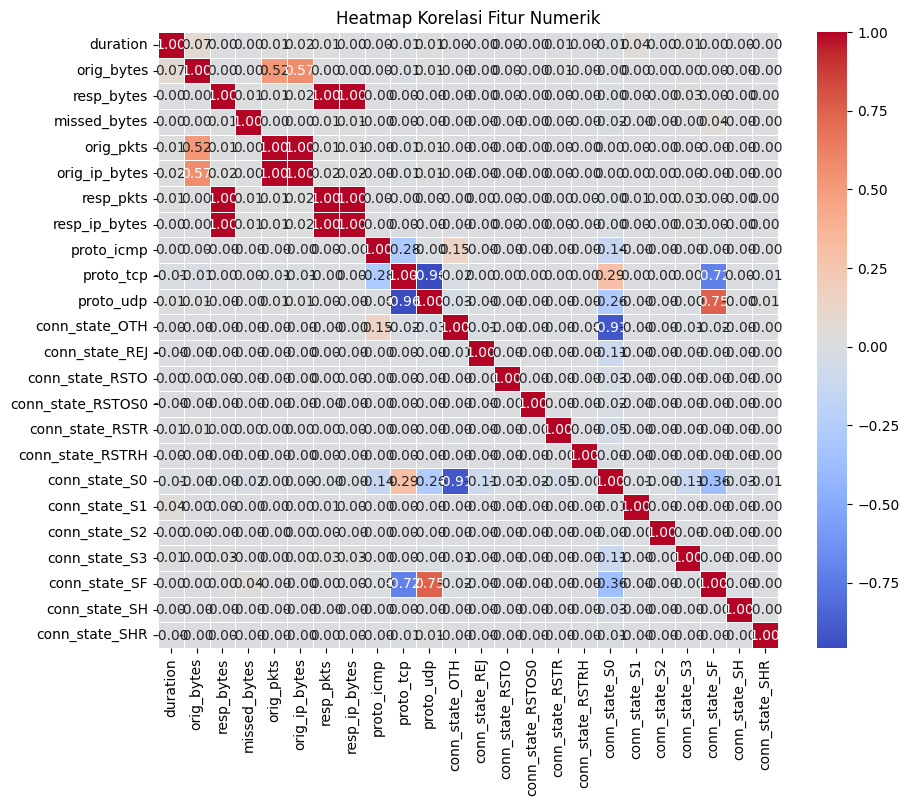

In [ ]:
# Hitung korelasi antar fitur numerik
correlation_matrix = df.corr(numeric_only=True)

# Buat heatmap
plt.figure(figsize=(10, 8))  # ukuran gambar heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

## 5. Declare Feature Vector and Target Variable

In [ ]:
Y = df[['label']]
print(Y.shape)
Y.tail()

(1377623, 1)


,label
1377618,PartOfAHorizontalPortScan
1377619,PartOfAHorizontalPortScan
1377620,Benign
1377621,Okiru
1377622,Okiru


In [ ]:
X = df.drop(['label'], axis=1)
print(X.shape)

(1377623, 24)


## 6. Normalisasi Data

In [ ]:
x = X.values
standard_scaler = StandardScaler()

x_scaled = standard_scaler.fit_transform(x)

X = pd.DataFrame(x_scaled, columns=X.columns)
X.tail()

,duration,orig_bytes,resp_bytes,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,proto_icmp,proto_tcp,...,conn_state_RSTOS0,conn_state_RSTR,conn_state_RSTRH,conn_state_S0,conn_state_S1,conn_state_S2,conn_state_S3,conn_state_SF,conn_state_SH,conn_state_SHR
1377618,-0.029249,-0.001454,-0.00091,-0.003934,-0.000914,-0.001029,-0.001056,-0.000916,-0.034206,0.121423,...,-0.005389,-0.01258,-0.001205,0.251531,-0.00241,-0.001205,-0.028397,-0.091653,-0.008731,-0.003188
1377619,0.002796,-0.001454,-0.00091,-0.003934,-0.000995,-0.001141,-0.001056,-0.000916,-0.034206,0.121423,...,-0.005389,-0.01258,-0.001205,0.251531,-0.00241,-0.001205,-0.028397,-0.091653,-0.008731,-0.003188
1377620,0.002796,-0.001454,-0.00091,-0.003934,-0.000995,-0.001085,-0.001056,-0.000916,-0.034206,0.121423,...,-0.005389,-0.01258,-0.001205,0.251531,-0.00241,-0.001205,-0.028397,-0.091653,-0.008731,-0.003188
1377621,-0.029249,-0.001454,-0.00091,-0.003934,-0.000914,-0.001029,-0.001056,-0.000916,-0.034206,0.121423,...,-0.005389,-0.01258,-0.001205,0.251531,-0.00241,-0.001205,-0.028397,-0.091653,-0.008731,-0.003188
1377622,0.002796,-0.001454,-0.00091,-0.003934,-0.000995,-0.001141,-0.001056,-0.000916,-0.034206,0.121423,...,-0.005389,-0.01258,-0.001205,0.251531,-0.00241,-0.001205,-0.028397,-0.091653,-0.008731,-0.003188


###

## 7. Feature Engineering

## a. Ubah label menjadi is_malicious

In [ ]:
# Mengubah label menjadi 'is_malicious', dimana 0 = Benign, 1 = Malicious
df['is_malicious'] = df['label'].apply(lambda x: 0 if x == 'Benign' else 1)

# Cek distribusi kelas setelah transformasi
print(df['is_malicious'].value_counts())

# Melakukan train-test split dengan label baru
X = df.drop(['label', 'is_malicious', 'resp_pkts', 'resp_bytes', 'orig_pkts'], axis=1)  # Menghapus kolom 'label' dan 'is_malicious' dari fitur
y = df['is_malicious']  # Menetapkan 'is_malicious' sebagai target label

is_malicious
0    688812
1    688811
Name: count, dtype: int64


## b. Cek kembali korelasi data

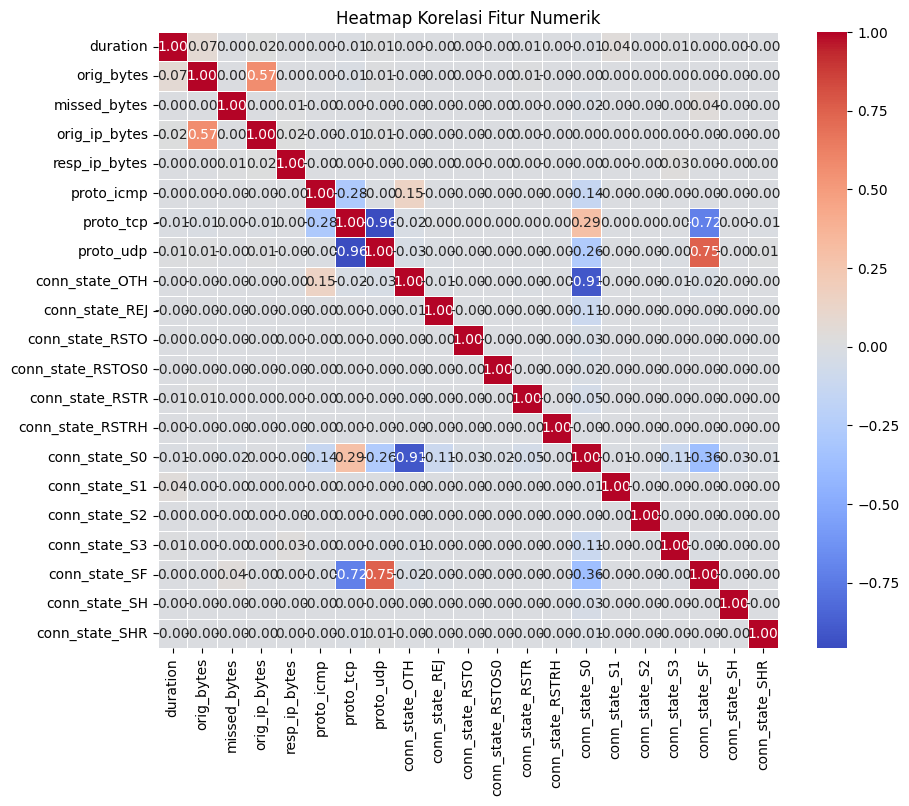

In [ ]:
# Hitung korelasi antar fitur numerik
correlation_matrix = X.corr(numeric_only=True)

# Buat heatmap
plt.figure(figsize=(10, 8))  # ukuran gambar heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

# Data Processing

## 1. Split Data into Separate Training and Test Set

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.33, random_state = 42)

In [ ]:
X_train.shape, X_test.shape

((923007, 21), (454616, 21))

In [ ]:
df['is_malicious'].unique()

array([0, 1])

## 1. Training Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train = pd.DataFrame(standard_scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(standard_scaler.transform(X_test), columns=X_train.columns)

In [ ]:
rfc = RandomForestClassifier(random_state=42)
rfc.fit(X_train, y_train.values.ravel())
y_pred = rfc.predict(X_test)

print('Model accuracy score with 10 decision-trees : {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Model accuracy score with 10 decision-trees : 0.8774


## 2. Evaluasi Model

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

# Menghitung Precision, Recall, dan F1-Score dengan zero_division=1 untuk menangani kelas tanpa prediksi
precision = precision_score(y_test, y_pred, average='weighted', zero_division=1)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=1)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=1)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Menampilkan Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=1))


Precision: 0.9004
Recall: 0.8774
F1-Score: 0.8756

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.76      0.86    227037
           1       0.80      1.00      0.89    227579

    accuracy                           0.88    454616
   macro avg       0.90      0.88      0.88    454616
weighted avg       0.90      0.88      0.88    454616



## 3. Confusion Matrix

In [ ]:
print(confusion_matrix(y_test, y_pred))

[[171960  55077]
 [   646 226933]]
